In [1]:
import math
import os

import h5py
import plotly.graph_objects as go
import tensorflow as tf
import numpy as np
import numpy.typing as npt
import numba

2025-06-04 19:42:22.184056: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-04 19:42:22.346590: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-06-04 19:42:22.346619: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-06-04 19:42:22.357724: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-04 19:42:22.390020: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-04 19:42:22.390885: I tensorflow/core/platform/cpu_feature_guard.cc:1

# Low variation of channel parameters with N_rx=1

In [2]:
ber_results = {}

data_base_path = "../docker/output/imdd"
data = [
    {
        "name": "µ=30 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx01-30km.hd5",
        "min_length": 25.0,
        "max_length": 35.0
    },
    {
        "name": "µ=45 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx01-45km.hd5",
        "min_length": 40.0,
        "max_length": 50.0
    },
    {
        "name": "µ=50 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx01-50km.hd5",
        "min_length": 45.0,
        "max_length": 55.0
    },
    {
        "name": "µ=55 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx01-55km.hd5",
        "min_length": 50.0,
        "max_length": 60.0
    }
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

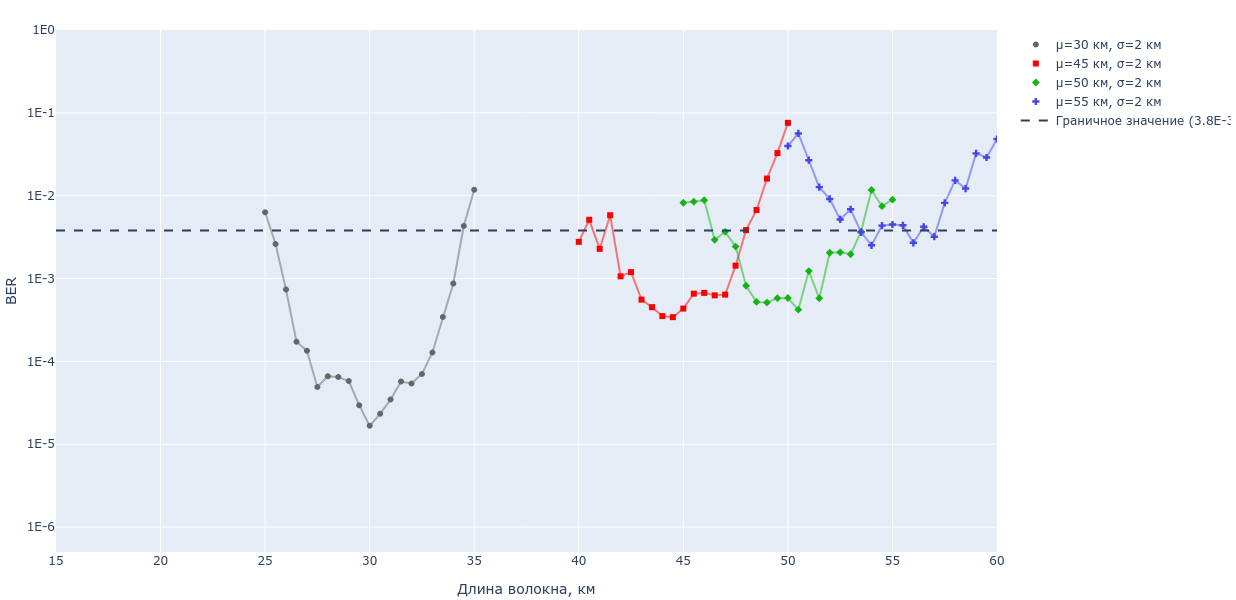

In [3]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 1, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[15.0, 60.0],
    yaxis_range=[-6.3, 0.0]
)

figure.show()

In [4]:
figure.write_image("ber_by_distance_N_rx01_low_variation.svg")

# Low variation of channel parameters with N_rx=15

In [ ]:
ber_results = {}

data_base_path = "../docker/output/imdd"
data = [
    {
        "name": "µ=30 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-30km.hd5",
        "min_length": 22.0,
        "max_length": 36.0
    },
    {
        "name": "µ=45 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-45km.hd5",
        "min_length": 38.0,
        "max_length": 51.0
    },
    {
        "name": "µ=50 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-50km.hd5",
        "min_length": 43.0,
        "max_length": 56.0
    },
    {
        "name": "µ=55 км, σ=2 км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-55km.hd5",
        "min_length": 49.0,
        "max_length": 62.0
    }
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

In [6]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 1, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[15.0, 65.0],
    yaxis_range=[-6.3, 0.0]
)

figure.show()

In [7]:
figure.write_image("ber_by_distance_N_rx15_low_variation.svg")

# High variation of channel parameters

In [8]:
ber_results = {}

data_base_path = "../docker/output/imdd"
data = [
    {
        "name": "0 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-0ps.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "4 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-4ps.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "11 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-11ps.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "17 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-17ps.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "19 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-19ps.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    }
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

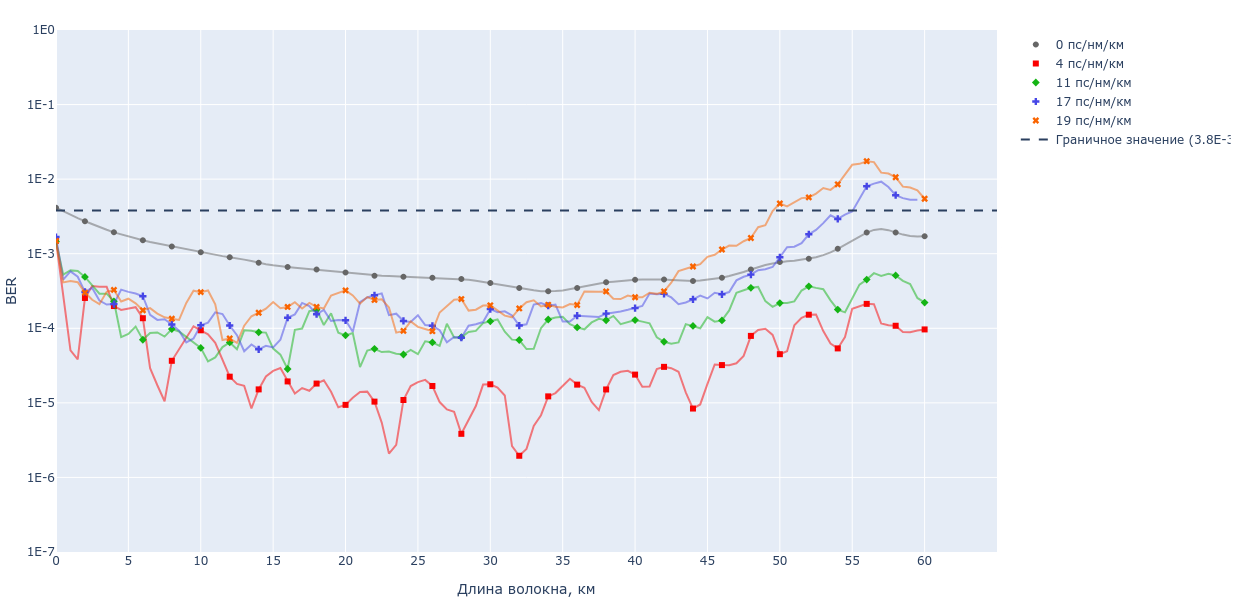

In [18]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-7", "1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 4, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::4],
            y=smoothed[::4],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[0.0, 65.0],
    yaxis_range=[-7, 0.0]
)

figure.show()

In [10]:
figure.write_image("ber_by_distance_high_variation.svg")

# Bit mapping optimization

In [19]:
with h5py.File("../docker/output/imdd/CM_imdd-M64-n48-N_tx25-N_rx15-17ps.hd5", "r") as f:
    confusion_matrix = tf.constant(f["confusion_matrix"], dtype=tf.int64)

In [30]:
@numba.njit
def _hamming_distance(x: int, y: int) -> int:
    xor = x ^ y
    distance = 0

    while xor != 0:
        distance += xor & 1
        xor >>= 1

    return distance


def _make_hamming_matrix(M: int) -> npt.NDArray:
    hamming_matrix = np.zeros((M, M), dtype=np.int16)

    for i in range(M):
        for j in range(M):
            hamming_matrix[i, j] = _hamming_distance(i, j)

    return hamming_matrix

M = tf.shape(confusion_matrix)[0]
hamming_matrix = tf.convert_to_tensor(_make_hamming_matrix(M), dtype=tf.int64)

In [31]:
total_symbol_errors = tf.math.reduce_sum(confusion_matrix) - tf.math.reduce_sum(
    tf.vectorized_map(lambda i: confusion_matrix[i, i], tf.range(M))
)
total_bit_errors = tf.math.reduce_sum(confusion_matrix * hamming_matrix)

In [32]:
total_symbol_errors, total_bit_errors

(<tf.Tensor: shape=(), dtype=int64, numpy=2411860>,
 <tf.Tensor: shape=(), dtype=int64, numpy=7407070>)

In [33]:
total_bit_errors / total_symbol_errors

<tf.Tensor: shape=(), dtype=float64, numpy=3.071102800328377>

# Bit mapping optimization results

In [96]:
ber_results = {}

with h5py.File("../docker/output/imdd/BER_imdd-M64-n48-N_tx25-N_rx15-17ps.hd5", "r") as f:
    ber, length = np.array(f["ber"]), np.array(f["channel__optical_fiber__length"])
    
    ber_results["До оптимизации"] = {
        "ber": ber,
        "length": length
    }

with h5py.File("../docker/output/imdd/BER_imdd-M64-n48-N_tx25-N_rx15-17ps-optimized-1.hd5", "r") as f:
    ber, length = np.array(f["ber"]), np.array(f["channel__optical_fiber__length"])
    
    ber_results["После оптимизации"] = {
        "ber": ber,
        "length": length
    }

ber_improvement = ber_results["До оптимизации"]["ber"] / ber_results["После оптимизации"]["ber"][:-1]
length = ber_results["До оптимизации"]["length"]

ber_results = {
    "Сокращение BER": {
        "ber": ber_improvement,
        "length": length
    }
}

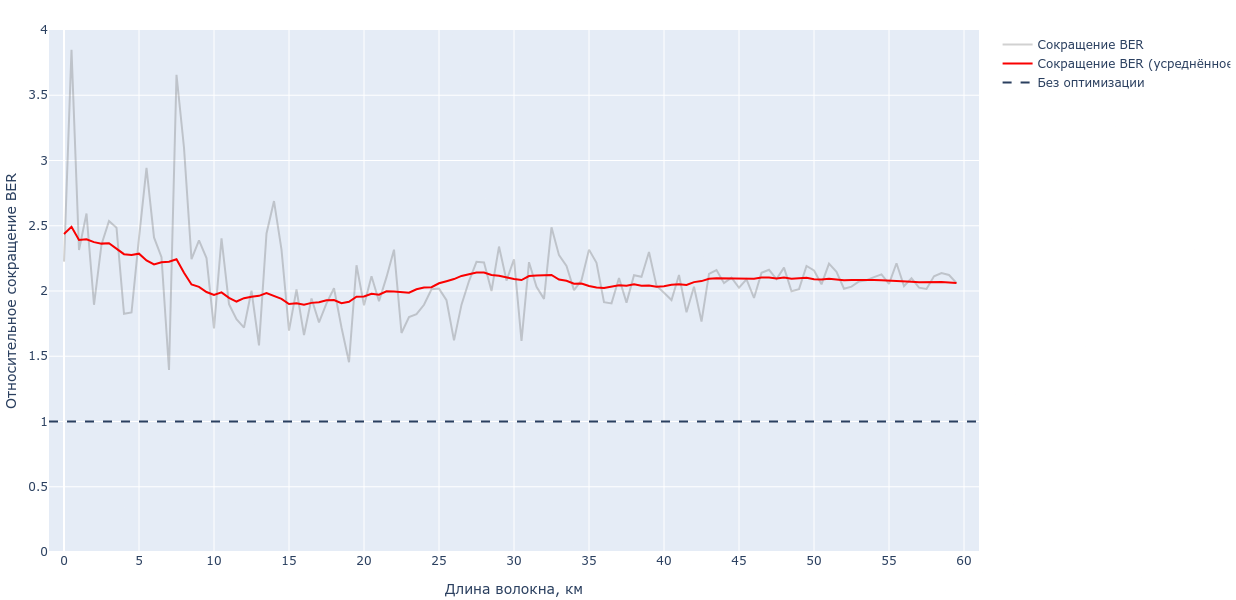

In [99]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]
    },
    yaxis={
        "title": "Относительное сокращение BER"
    }
))

colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

color = "#666"
smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 16, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)

name = "Сокращение BER"
ber_result = ber_results[name]

figure.add_trace(
    go.Scatter(
        x=ber_result["length"][::1],
        y=ber_result["ber"][::1],
        name=name,
        mode="lines",
        line={"color": "#666"},
        opacity=0.3,
        showlegend=True
    )
)

figure.add_trace(
    go.Scatter(
        x=ber_result["length"][::1],
        y=smoothed[::1],
        name=f"{name} (усреднённое)",
        mode="lines",
        opacity=1.0,
        line={"color": "rgb(250, 0, 0)"}
    )
)

#figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.add_hline(1.0, line_dash="dash", name="Без оптимизации", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[-1.0, 61.0],
    yaxis_range=[0.0, 4]
)

figure.show()

In [100]:
figure.write_image("ber_reduction.svg")

In [101]:
ber_results = {}

data_base_path = "../docker/output/imdd"
data = [
    {
        "name": "0 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-0ps-optimized-1.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "4 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-4ps-optimized-1.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "11 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-11ps-optimized-1.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "17 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-17ps-optimized-1.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    },
    {
        "name": "19 пс/нм/км",
        "file": "BER_imdd-M64-n48-N_tx25-N_rx15-19ps-optimized-1.hd5",
        "min_length": 0.0,
        "max_length": 60.0
    }
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

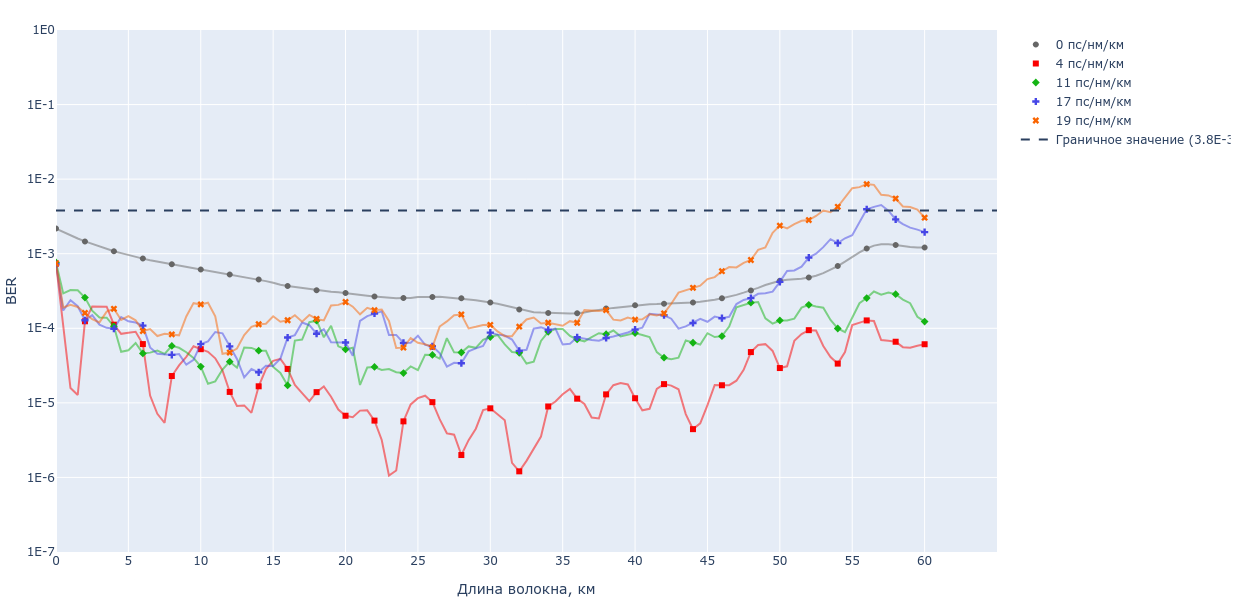

In [102]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-7", "1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 4, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::4],
            y=smoothed[::4],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[0.0, 65.0],
    yaxis_range=[-7, 0.0]
)

figure.show()

In [103]:
figure.write_image("ber_by_distance_high_variation_optimized.svg")

# Coherent Autoencoder

## No phase noise

In [55]:
ber_results = {}

data_base_path = "../docker/output/iq"
data = [
    {
        "name": "17 пс/нм/км, N_rx=1",
        "file": "BER_iq-M64-n96-N_tx25-N_rx01-TX3-RX15-no-phase-noise-uniform_0-105km-17ps.hd5",
        "min_length": 0.0,
        "max_length": 105.0
    },
    {
        "name": "17 пс/нм/км, N_rx=11",
        "file": "BER_iq-M64-n96-N_tx25-N_rx11-TX3-RX15-no-phase-noise-uniform_0-105km-17ps.hd5",
        "min_length": 0.0,
        "max_length": 105.0
    },
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

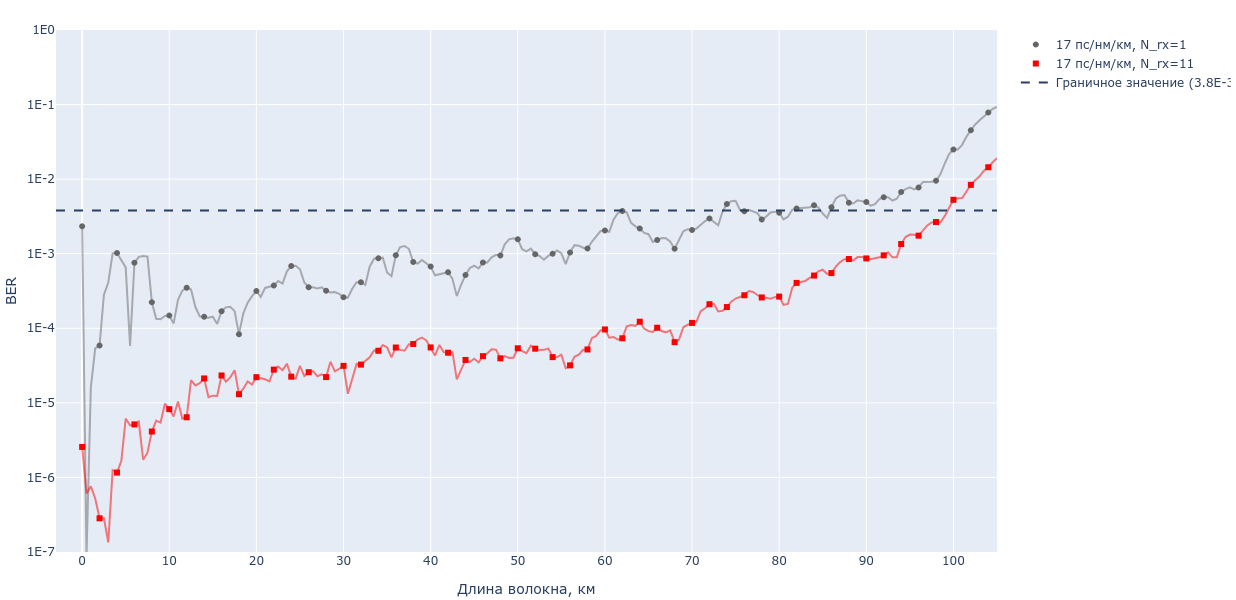

In [56]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 100.0, 110.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-7", "1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 4, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::4],
            y=smoothed[::4],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[-3.0, 105.0],
    yaxis_range=[-7, 0.0]
)

figure.show()

In [57]:
figure.write_image("ber_by_distance_iq_no_phase_noise.svg")

## With Phase Noise and 30000 Symbols

In [58]:
ber_results = {}

data_base_path = "../docker/output/iq"
data = [
    {
        "name": "17 пс/нм/км, N_rx=1",
        "file": "BER_iq-M64-n96-N_tx25-N_rx01-TX3-RX15-with-full-phase-noise-uniform_0-105km-17ps-30k.hd5",
        "min_length": 0.0,
        "max_length": 105.0
    },
    {
        "name": "17 пс/нм/км, N_rx=11",
        "file": "BER_iq-M64-n96-N_tx25-N_rx11-TX3-RX15-with-full-phase-noise-uniform_0-105km-17ps-30k.hd5",
        "min_length": 0.0,
        "max_length": 105.0
    },
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

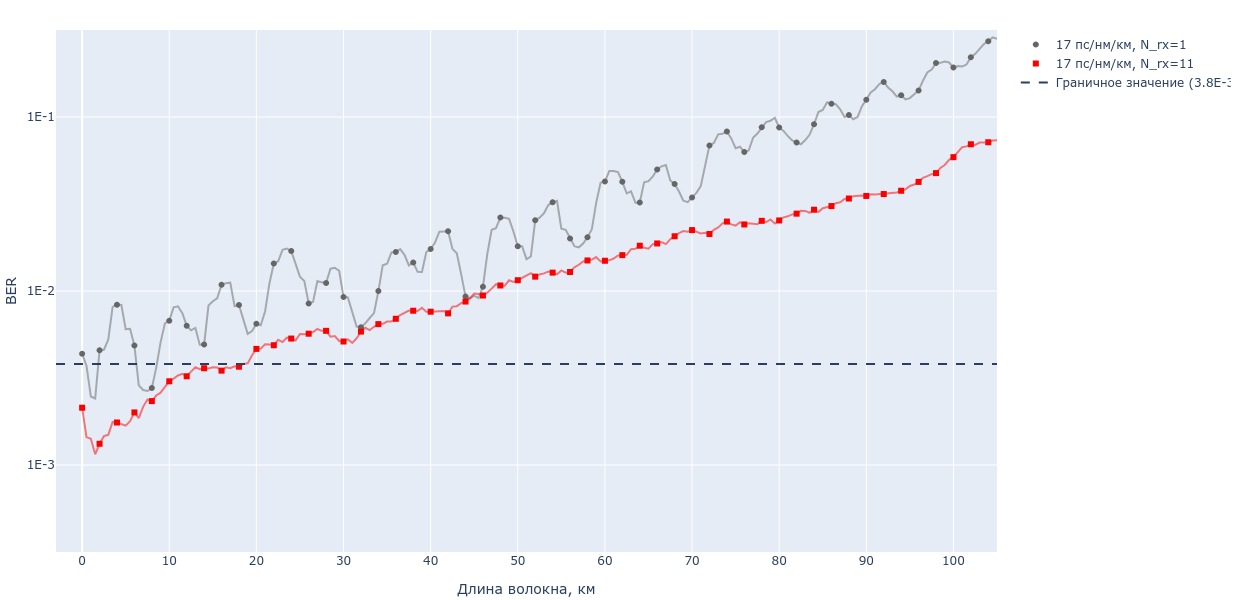

In [59]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 100.0, 110.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-7", "1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 6, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::4],
            y=smoothed[::4],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[-3.0, 105.0],
    yaxis_range=[-3.5, -0.5]
)

figure.show()

In [60]:
figure.write_image("ber_by_distance_iq_full_phase_noise.svg")

## With Phase Noise and 1000 Symbols

In [61]:
ber_results = {}

data_base_path = "../docker/output/iq"
data = [
    {
        "name": "17 пс/нм/км, N_rx=1",
        "file": "BER_iq-M64-n96-N_tx25-N_rx01-TX3-RX15-with-phase-noise-uniform_0-105km-17ps.hd5",
        "min_length": 0.0,
        "max_length": 105.0
    },
    {
        "name": "17 пс/нм/км, N_rx=11",
        "file": "BER_iq-M64-n96-N_tx25-N_rx11-TX3-RX15-with-phase-noise-uniform_0-105km-17ps.hd5",
        "min_length": 0.0,
        "max_length": 105.0
    },
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber, length = list(f["ber"]), list(f["channel__optical_fiber__length"])
        min_length = entry["min_length"]
        max_length = entry["max_length"]

        ber, length = list(
            zip(*list(filter(lambda x: x[1] >= min_length and x[1] <= max_length, zip(ber, length))))
        )
        
        ber_results[entry["name"]] = {
            "ber": ber,
            "length": length
        }

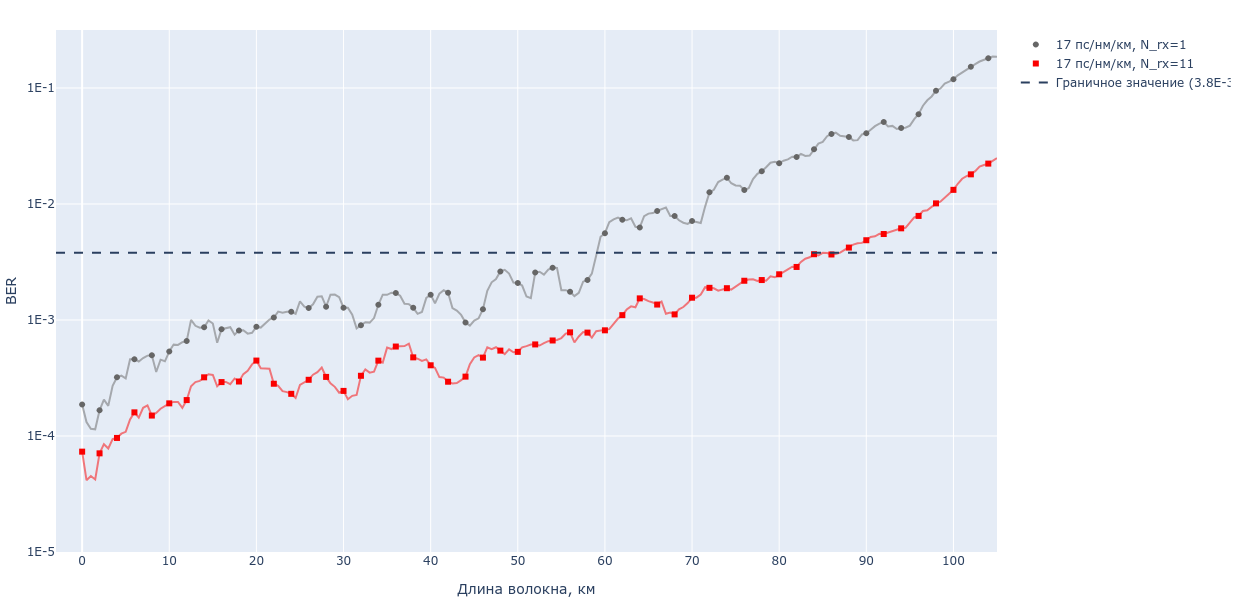

In [62]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 100.0, 110.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-7", "1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 6, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::4],
            y=smoothed[::4],
            name=name,
            mode="markers",
            marker=dict(size=6, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[-3.0, 105.0],
    yaxis_range=[-5, -0.5]
)

figure.show()

In [63]:
figure.write_image("ber_by_distance_iq_partial_phase_noise.svg")